# LAB 7

## Part A - Image Representation

In [2]:
from pathlib import Path

data_dir = Path("att_faces")

print("Dataset folder exists:", data_dir.exists())

if data_dir.exists():
    subjects = sorted(
        folder for folder in data_dir.iterdir()
        if folder.is_dir() and folder.name.startswith("s")
    )
    images = list(data_dir.glob("s*/*.pgm"))

    print("Subject folders:", len(subjects))
    print("Total images:", len(images))

Dataset folder exists: True
Subject folders: 40
Total images: 400


### Load and inspect the images

In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Path to the extracted ORL face dataset
data_dir = Path("att_faces")

# Sort subject folders numerically: s1, s2, ..., s40
subject_folders = sorted(
    [folder for folder in data_dir.iterdir()
     if folder.is_dir() and folder.name.startswith("s")],
    key=lambda folder: int(folder.name[1:])
)

print("Number of subjects:", len(subject_folders))

# Load one image to inspect its pixel representation
sample_path = subject_folders[0] / "1.pgm"

sample_image = Image.open(sample_path).convert("L")
sample_array = np.array(sample_image)

print("Image dimensions:", sample_array.shape)
print("Minimum intensity:", sample_array.min())
print("Maximum intensity:", sample_array.max())
print("Data type:", sample_array.dtype)


Number of subjects: 40
Image dimensions: (112, 92)
Minimum intensity: 11
Maximum intensity: 234
Data type: uint8


### Flatten each image into a feature vector

In [4]:
# Store image vectors and their subject labels
# Each face image is converted into a one-dimensional vector using NumPy's `flatten()` operation.
#  The vectors are stacked row-wise to form a feature matrix, where each row represents one image and each column represents a pixel position.

image_vectors = []
image_labels = []

for folder in subject_folders:

    # Process images in numerical order
    image_paths = sorted(
        folder.glob("*.pgm"),
        key=lambda path: int(path.stem)
    )

    for image_path in image_paths:
        # Read the image as grayscale
        image = Image.open(image_path).convert("L")
        image_array = np.array(image, dtype=np.uint8)

        # Convert the 2D image into a 1D pixel vector
        image_vectors.append(image_array.flatten())

        # Use the subject folder as the class label
        image_labels.append(folder.name)

# Combine individual vectors into one matrix
X_pixels = np.array(image_vectors, dtype=np.uint8)
y = np.array(image_labels)

# Normalize pixel intensities to the range [0, 1]
X = X_pixels.astype(np.float64) / 255.0

print("Original pixel matrix shape:", X_pixels.shape)
print("Normalized feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Unique subjects:", len(np.unique(y)))
print("Normalized pixel range:", X.min(), "to", X.max())

Original pixel matrix shape: (400, 10304)
Normalized feature matrix shape: (400, 10304)
Label array shape: (400,)
Unique subjects: 40
Normalized pixel range: 0.0 to 0.984313725490196


**Observation:** The dataset contains 400 images represented by 10,304 pixel features each. The feature matrix has 400 rows and 10,304 columns, while the label array stores the corresponding subject for each image. Normalization scales the pixel intensities from 0–255 to 0–1, which makes numerical processing convenient.

### Create train-test split

In [5]:
# Fixed seed ensures the same split each time
rng = np.random.default_rng(42)

train_indices = []
test_indices = []

# Split each subject's images independently
for subject in np.unique(y):
    subject_indices = np.where(y == subject)[0]

    # Shuffle the image indices for this subject
    subject_indices = rng.permutation(subject_indices)

    # Use 7 images for training and 3 for testing
    train_indices.extend(subject_indices[:7])
    test_indices.extend(subject_indices[7:])

# Convert the index lists into NumPy arrays
train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

# Create the corresponding datasets
X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))

Training images: 280
Testing images: 120
Training feature shape: (280, 10304)
Testing feature shape: (120, 10304)
Subjects in training: 40
Subjects in testing: 40


**Observation:** The ORL dataset has been converted into a numerical feature matrix, with one row per image and one column per pixel. A reproducible subject-wise split provides 280 training images and 120 testing images, ensuring that every subject is represented in both sets.

The training set will be used to calculate the mean face and principal components. The testing set will be kept separate for evaluating recognition performance.

## Part B - PCA, Eigenfaces and Compression

Principal Component Analysis (PCA) reduces the number of features while preserving as much variation in the data as possible. In this part, we will calculate the mean face, center the training images, implement PCA using covariance eigendecomposition and Singular Value Decomposition (SVD), and compare their results.

### Calculate the mean face and center the training data

In [6]:
# Calculate the average pixel intensity across training images
mean_face = np.mean(X_train, axis=0)

# Center the training and testing data using the training mean
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training data shape:", X_train_centered.shape)
print("Centered test data shape:", X_test_centered.shape)
print("Mean of centered training data:", X_train_centered.mean())

Mean face shape: (10304,)
Centered training data shape: (280, 10304)
Centered test data shape: (120, 10304)
Mean of centered training data: -8.133097862737615e-17


**Observation:** The mean face represents the average pixel intensity at every position across the training images. Centering subtracts this average from each image, allowing PCA to capture patterns of variation among faces rather than differences caused by the overall mean.

### PCA using covariance and eigendecomposition

In [8]:
# Number of training images
n_train = X_train_centered.shape[0]

# Compute the Gram matrix instead of the large pixel covariance matrix
gram_matrix = X_train_centered @ X_train_centered.T

# Eigendecomposition of the symmetric Gram matrix
eigenvalues, eigenvectors = np.linalg.eigh(gram_matrix)

# Sort eigenvalues from largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Remove tiny numerical eigenvalues
tolerance = np.finfo(float).eps * max(gram_matrix.shape) * max(
    abs(eigenvalues[0]), 1.0
)
valid = eigenvalues > tolerance

eigenvalues = eigenvalues[valid]
eigenvectors = eigenvectors[:, valid]

# Convert eigenvectors into principal directions in pixel space
principal_components_eig = (
    X_train_centered.T @ eigenvectors
) / np.sqrt(eigenvalues)

# Normalize the principal directions
principal_components_eig /= np.linalg.norm(
    principal_components_eig, axis=0
)

# Explained variance ratio
explained_variance_eig = eigenvalues / (n_train - 1)
variance_ratio_eig = explained_variance_eig / explained_variance_eig.sum()

print("Gram matrix shape:", gram_matrix.shape)
print("Principal components shape:", principal_components_eig.shape)
print("Number of non-zero components:", len(eigenvalues))
print("Total explained variance ratio:", variance_ratio_eig.sum())

Gram matrix shape: (280, 280)
Principal components shape: (10304, 279)
Number of non-zero components: 279
Total explained variance ratio: 1.0


### PCA using SVD

In [9]:
# Perform SVD on the centered training data
U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Principal directions are the rows of Vt
principal_components_svd = Vt.T

# Variance associated with each principal component
explained_variance_svd = singular_values**2 / (n_train - 1)

# Proportion of total variance explained by each component
variance_ratio_svd = (
    explained_variance_svd / explained_variance_svd.sum()
)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("Vt shape:", Vt.shape)
print("Principal component shape:", principal_components_svd.shape)
print("Total explained variance ratio:", variance_ratio_svd.sum())

U shape: (280, 280)
Singular values shape: (280,)
Vt shape: (280, 10304)
Principal component shape: (10304, 280)
Total explained variance ratio: 1.0


In [10]:
# Compare the leading eigenvalues from the two approaches
num_to_compare = min(
    len(eigenvalues),
    len(singular_values)
)

variance_from_eig = eigenvalues[:num_to_compare] / (n_train - 1)
variance_from_svd = singular_values[:num_to_compare]**2 / (n_train - 1)

print("First five variances from eigendecomposition:")
print(variance_from_eig[:5])

print("\nFirst five variances from SVD:")
print(variance_from_svd[:5])

print("\nMaximum absolute difference:")
print(np.max(np.abs(variance_from_eig - variance_from_svd)))

First five variances from eigendecomposition:
[43.70412622 32.3532577  17.47654602 13.80635138 12.82319298]

First five variances from SVD:
[43.70412622 32.3532577  17.47654602 13.80635138 12.82319298]

Maximum absolute difference:
9.947598300641403e-14


**Comparison:** Covariance eigendecomposition and SVD are two approaches to finding the principal directions. We used the smaller Gram matrix for eigendecomposition because the number of training images is much smaller than the number of pixel features. SVD directly factorizes the centered data matrix.


### Variance and selecting components

Components needed for 90% variance: 92
Cumulative variance preserved: 0.9001810415654964


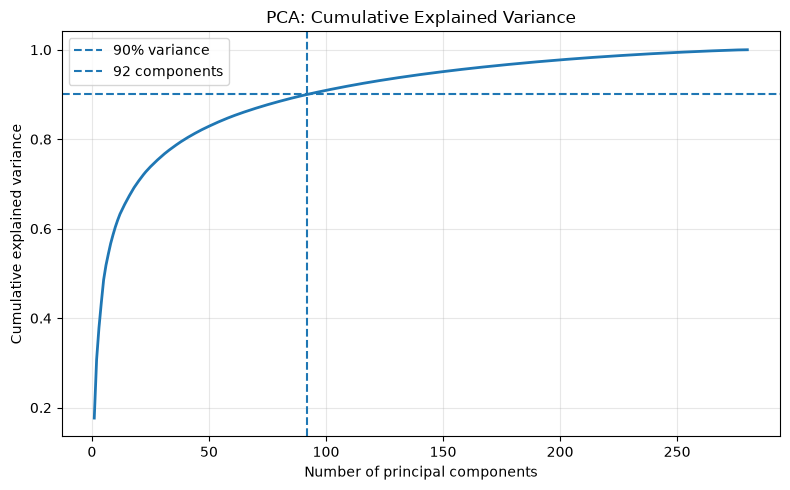

In [11]:
# Cumulative explained variance from the SVD results
cumulative_variance = np.cumsum(variance_ratio_svd)

# Find the minimum number of components needed for 90% variance
n_components_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

print("Components needed for 90% variance:", n_components_90)
print(
    "Cumulative variance preserved:",
    cumulative_variance[n_components_90 - 1]
)

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)
plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance"
)
plt.axvline(
    x=n_components_90,
    linestyle="--",
    label=f"{n_components_90} components"
)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation:** Eigenfaces represent the dominant patterns of variation in the training faces. Early components generally capture larger-scale changes, while later components represent progressively smaller variations. Their pixel intensities can be positive or negative because the components describe deviations from the mean face, not ordinary grayscale photographs.

### Project faces into PCA space

In [13]:
# Keep the minimum number of components required for 90% variance
W = principal_components_svd[:, :n_components_90]

# Project the training and test images into PCA space
Z_train = X_train_centered @ W
Z_test = X_test_centered @ W

print("Selected components:", n_components_90)
print("Reduced training shape:", Z_train.shape)
print("Reduced testing shape:", Z_test.shape)

Selected components: 92
Reduced training shape: (280, 92)
Reduced testing shape: (120, 92)


### Reconstruct faces and compare storage

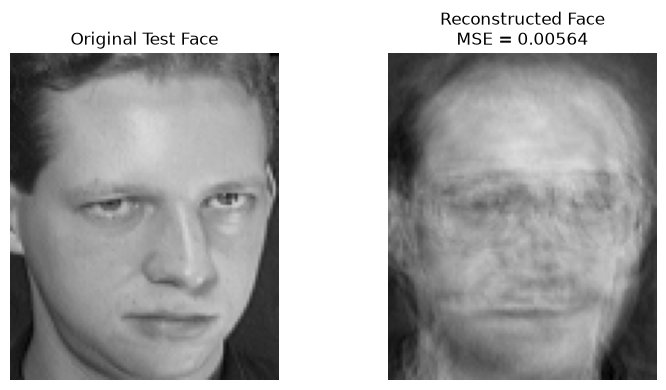

Reconstruction MSE: 0.0056365613574241615
Original training pixel values: 2885120
Reduced training values: 25760
PCA model values: 958272
Per-image value reduction: 99.11%
Total value reduction including PCA model: 65.89%


In [16]:
# Reconstruct test images from their reduced PCA representations
X_test_reconstructed = Z_test @ W.T + mean_face

# Select a test image for visual comparison
sample_index = 0

original_face = X_test[sample_index].reshape(112, 92)
reconstructed_face = X_test_reconstructed[sample_index].reshape(112, 92)

# Mean squared reconstruction error
reconstruction_mse = np.mean(
    (X_test[sample_index] - X_test_reconstructed[sample_index])**2
)

# Compare the original and reconstructed images
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_face, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Test Face")
axes[0].axis("off")

axes[1].imshow(
    np.clip(reconstructed_face, 0, 1),
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title(f"Reconstructed Face\nMSE = {reconstruction_mse:.5f}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Reconstruction MSE:", reconstruction_mse)

# Original representation: all grayscale pixels
original_values = X_train.shape[0] * X_train.shape[1]

# Reduced representation: PCA scores for each training image
reduced_values = Z_train.size

# PCA model: mean face plus selected principal directions
model_values = mean_face.size + W.size

print("Original training pixel values:", original_values)
print("Reduced training values:", reduced_values)
print("PCA model values:", model_values)

# Storage ratio for per-image representations
print(
    "Per-image value reduction: "
    f"{100 * (1 - Z_train.shape[1] / X_train.shape[1]):.2f}%"
)

# Total numerical values, including the PCA model
print(
    "Total value reduction including PCA model: "
    f"{100 * (1 - (reduced_values + model_values) / original_values):.2f}%"
)

**Conclusion:** 

PCA was implemented using NumPy through covariance eigendecomposition and Singular Value Decomposition (SVD). The cumulative explained variance was used to select the minimum number of principal components required to preserve at least 90% of the training data's variance.

The eigenfaces represent the major patterns of variation among the training images. The selected components were used to project the images into a lower-dimensional space and reconstruct the test images.

The reconstructed face retained the overall facial structure, although some fine details were lost. The reconstruction MSE for the displayed test image was approximately 0.00564.

The reduced training representation required 25,760 numerical values, compared with 2,885,120 original pixel values. The estimated reduction was 99.11% for the per-image representation and 65.89% when the PCA model was included. These percentages describe numerical value counts rather than actual file sizes.

## Part C - Recognition in PCA Space

### Implement nearest-face matching

In [17]:
# Find the nearest training face for each test image
def nearest_face_predictions(X_train_features, X_test_features, y_train):
    predictions = []
    nearest_indices = []
    nearest_distances = []

    for test_vector in X_test_features:
        # Euclidean distance from this test image to every training image
        distances = np.linalg.norm(
            X_train_features - test_vector,
            axis=1
        )

        # Index of the closest training image
        nearest_index = np.argmin(distances)

        predictions.append(y_train[nearest_index])
        nearest_indices.append(nearest_index)
        nearest_distances.append(distances[nearest_index])

    return (
        np.array(predictions),
        np.array(nearest_indices),
        np.array(nearest_distances)
    )


# Recognition using raw pixels
raw_predictions, raw_nearest_indices, raw_distances = (
    nearest_face_predictions(X_train, X_test, y_train)
)

# Recognition using PCA features
pca_predictions, pca_nearest_indices, pca_distances = (
    nearest_face_predictions(Z_train, Z_test, y_train)
)

# Calculate recognition accuracy
raw_accuracy = np.mean(raw_predictions == y_test)
pca_accuracy = np.mean(pca_predictions == y_test)

print(f"Raw-pixel recognition accuracy: {raw_accuracy:.2%}")
print(f"PCA-space recognition accuracy: {pca_accuracy:.2%}")

Raw-pixel recognition accuracy: 97.50%
PCA-space recognition accuracy: 97.50%


### Inspect correct and incorrect matches

Correct predictions: 117
Incorrect predictions: 3


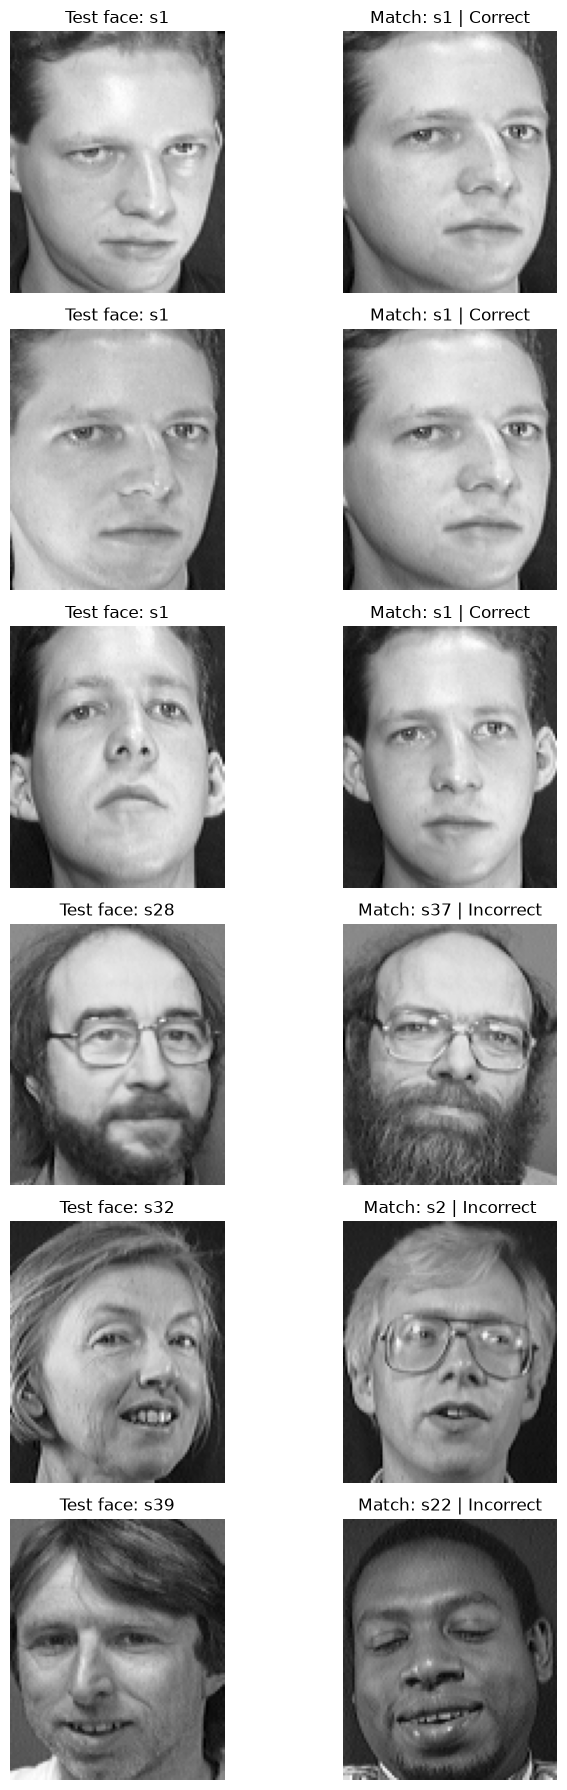

In [19]:
# Display a few correct and incorrect PCA recognition results
correct_indices = np.where(pca_predictions == y_test)[0]
incorrect_indices = np.where(pca_predictions != y_test)[0]

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))

# Select up to three examples from each group
examples = list(correct_indices[:3]) + list(incorrect_indices[:3])

if examples:
    fig, axes = plt.subplots(
        len(examples), 2,
        figsize=(8, 3 * len(examples)),
        squeeze=False
    )

    for row, test_index in enumerate(examples):
        # Find the original test image
        original_index = test_indices[test_index]
        test_face = X[original_index].reshape(112, 92)

        # Find the nearest training image
        train_index = train_indices[pca_nearest_indices[test_index]]
        matched_face = X[train_index].reshape(112, 92)

        actual_label = y_test[test_index]
        predicted_label = pca_predictions[test_index]

        status = (
            "Correct"
            if actual_label == predicted_label
            else "Incorrect"
        )

        axes[row, 0].imshow(test_face, cmap="gray")
        axes[row, 0].set_title(f"Test face: {actual_label}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(matched_face, cmap="gray")
        axes[row, 1].set_title(
            f"Match: {predicted_label} | {status}"
        )
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()

In [20]:
# Check the consistency of the PCA recognition results
print("Total test images:", len(y_test))
print("Correct predictions:", np.sum(pca_predictions == y_test))
print("Incorrect predictions:", np.sum(pca_predictions != y_test))
print("Calculated accuracy:", np.mean(pca_predictions == y_test))

# Confirm that every predicted subject exists in the training set
print(
    "All predicted subjects exist in training:",
    set(pca_predictions).issubset(set(y_train))
)

Total test images: 120
Correct predictions: 117
Incorrect predictions: 3
Calculated accuracy: 0.975
All predicted subjects exist in training: True


**Conclusion:** 

The nearest-neighbour approach was used to identify test faces by calculating the Euclidean distance between each test image and all stored training images. The subject label of the closest training image was assigned as the prediction.

Two representations were evaluated: normalized raw-pixel features and reduced PCA features.

| Method | Correct Predictions | Incorrect Predictions | Accuracy |
|---|---:|---:|---:|
| Raw-pixel nearest face | 117/120 | 3/120 | 97.50% |
| PCA-space nearest face | 117/120 | 3/120 | 97.50% |

Both methods achieved an accuracy of 97.50% on the test set. The raw-pixel method used 10,304 features per image, whereas PCA used the reduced representation selected to preserve at least 90% of the training data's variance.

The correct and incorrect match visualizations helped assess individual predictions. Some test faces were matched to images of different subjects, demonstrating that the nearest image in feature space does not always represent the correct identity.

PCA reduced the dimensionality of the face representations while maintaining the same overall recognition accuracy as raw-pixel matching on this train-test split. Euclidean nearest-neighbour matching therefore provides a useful baseline for comparison with traditional machine-learning classifiers in Part D.

## Part D - Traditional Machine Learning

### Train three classifiers


In this part, three traditional machine-learning classifiers are evaluated using the PCA representations generated in Part B: K-Nearest Neighbours (KNN), Support Vector Machine (SVM), and Logistic Regression.

All three classifiers use the same training and testing split. Their performance is compared with the Euclidean nearest-face baseline established in Part C.

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Train KNN on the reduced PCA features
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(Z_train, y_train)

knn_predictions = knn_model.predict(Z_test)
knn_accuracy = accuracy_score(y_test, knn_predictions)


# Train an SVM with an RBF kernel
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)
svm_model.fit(Z_train, y_train)

svm_predictions = svm_model.predict(Z_test)
svm_accuracy = accuracy_score(y_test, svm_predictions)


# Train Logistic Regression as a linear baseline
logistic_model = LogisticRegression(
    C=1.0,
    max_iter=3000,
    random_state=42
)
logistic_model.fit(Z_train, y_train)

logistic_predictions = logistic_model.predict(Z_test)
logistic_accuracy = accuracy_score(y_test, logistic_predictions)


# Compare the baseline and the three classifiers
comparison_df = pd.DataFrame({
    "Method": [
        "Raw-pixel nearest face",
        "PCA nearest face",
        "PCA + KNN (k=3)",
        "PCA + SVM (RBF)",
        "PCA + Logistic Regression"
    ],
    "Accuracy": [
        raw_accuracy,
        pca_accuracy,
        knn_accuracy,
        svm_accuracy,
        logistic_accuracy
    ]
})

display(
    comparison_df.style.format({"Accuracy": "{:.2%}"})
)

,Method,Accuracy
0,Raw-pixel nearest face,97.50%
1,PCA nearest face,97.50%
2,PCA + KNN (k=3),93.33%
3,PCA + SVM (RBF),98.33%
4,PCA + Logistic Regression,99.17%


In [22]:
# Print detailed metrics for each traditional classifier
model_predictions = {
    "KNN": knn_predictions,
    "SVM": svm_predictions,
    "Logistic Regression": logistic_predictions
}

for model_name, predictions in model_predictions.items():
    print(f"\n{'=' * 55}")
    print(model_name)
    print(f"{'=' * 55}")

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))


KNN
              precision    recall  f1-score   support

          s1       0.75      1.00      0.86         3
         s10       1.00      1.00      1.00         3
         s11       1.00      1.00      1.00         3
         s12       1.00      1.00      1.00         3
         s13       1.00      1.00      1.00         3
         s14       1.00      1.00      1.00         3
         s15       1.00      1.00      1.00         3
         s16       1.00      0.67      0.80         3
         s17       1.00      0.67      0.80         3
         s18       1.00      1.00      1.00         3
         s19       1.00      1.00      1.00         3
          s2       0.75      1.00      0.86         3
         s20       1.00      0.67      0.80         3
         s21       1.00      1.00      1.00         3
         s22       1.00      1.00      1.00         3
         s23       1.00      1.00      1.00         3
         s24       1.00      1.00      1.00         3
         s25       0.7

### Experiment with the number of PCA components

,Variance Threshold,Components,KNN Accuracy,SVM Accuracy,Logistic Regression Accuracy
0,50%,6,83.33%,90.83%,80.00%
1,75%,28,93.33%,98.33%,99.17%
2,90%,92,93.33%,98.33%,99.17%
3,95%,149,93.33%,98.33%,99.17%


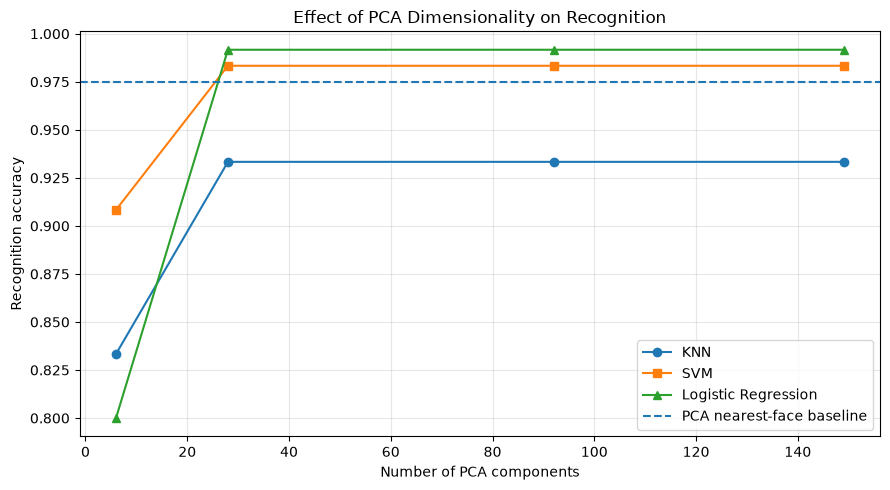

In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

# Variance thresholds to compare
variance_thresholds = [0.50, 0.75, 0.90, 0.95]

experiment_results = []

for threshold in variance_thresholds:

    # Find the minimum number of components for this threshold
    n_components = np.searchsorted(
        cumulative_variance, threshold
    ) + 1

    # Select the corresponding PCA directions
    components = principal_components_svd[:, :n_components]

    # Project the training and test data
    Z_train_exp = X_train_centered @ components
    Z_test_exp = X_test_centered @ components

    # KNN classifier
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(Z_train_exp, y_train)
    knn_accuracy_exp = accuracy_score(
        y_test, knn.predict(Z_test_exp)
    )

    # SVM classifier
    svm = SVC(kernel="rbf", C=10, gamma="scale")
    svm.fit(Z_train_exp, y_train)
    svm_accuracy_exp = accuracy_score(
        y_test, svm.predict(Z_test_exp)
    )

    # Logistic Regression classifier
    logistic = LogisticRegression(
        C=1.0,
        max_iter=3000,
        random_state=42
    )
    logistic.fit(Z_train_exp, y_train)
    logistic_accuracy_exp = accuracy_score(
        y_test, logistic.predict(Z_test_exp)
    )

    # Save the results for comparison
    experiment_results.append({
        "Variance Threshold": f"{threshold:.0%}",
        "Components": n_components,
        "KNN Accuracy": knn_accuracy_exp,
        "SVM Accuracy": svm_accuracy_exp,
        "Logistic Regression Accuracy": logistic_accuracy_exp
    })

# Display the comparison table
experiment_df = pd.DataFrame(experiment_results)

display(
    experiment_df.style.format({
        "KNN Accuracy": "{:.2%}",
        "SVM Accuracy": "{:.2%}",
        "Logistic Regression Accuracy": "{:.2%}"
    })
)

# Plot recognition accuracy against the number of components
plt.figure(figsize=(9, 5))

plt.plot(
    experiment_df["Components"],
    experiment_df["KNN Accuracy"],
    marker="o",
    label="KNN"
)

plt.plot(
    experiment_df["Components"],
    experiment_df["SVM Accuracy"],
    marker="s",
    label="SVM"
)

plt.plot(
    experiment_df["Components"],
    experiment_df["Logistic Regression Accuracy"],
    marker="^",
    label="Logistic Regression"
)

plt.axhline(
    pca_accuracy,
    linestyle="--",
    label="PCA nearest-face baseline"
)

plt.xlabel("Number of PCA components")
plt.ylabel("Recognition accuracy")
plt.title("Effect of PCA Dimensionality on Recognition")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The number of retained principal components was varied using explained-variance thresholds of 50%, 75%, 90%, and 95%. KNN, SVM, and Logistic Regression were evaluated using each representation.

At 50% explained variance, the models achieved accuracies of 83.33%, 90.83%, and 80.00%, respectively. Increasing the retained variance to 75% improved their accuracies to 93.33% for KNN, 98.33% for SVM, and 99.17% for Logistic Regression.

The results remained unchanged when the variance threshold increased to 90% and 95%. Logistic Regression achieved the highest observed accuracy of 99.17% using 28 principal components, compared with 10,304 original pixel features.

These results suggest that a compact PCA representation can retain sufficient information for effective face classification on this test split. Increasing the number of components beyond 28 did not improve the observed accuracy for these models.


### Hyperparameter Tuning.

In [24]:
# Prepare PCA representations for the two selected component counts
component_options = [28, 92]
pca_datasets = {}

for n_components in component_options:
    # Select the leading principal directions
    components = principal_components_svd[:, :n_components]

    # Project training and test images using the same directions
    Z_train_current = X_train_centered @ components
    Z_test_current = X_test_centered @ components

    pca_datasets[n_components] = (
        Z_train_current,
        Z_test_current
    )

    print(f"{n_components} components:")
    print("  Training shape:", Z_train_current.shape)
    print("  Testing shape:", Z_test_current.shape)

28 components:
  Training shape: (280, 28)
  Testing shape: (120, 28)
92 components:
  Training shape: (280, 92)
  Testing shape: (120, 92)


### Tune all three classifiers using cross-validation

In [25]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Use the same cross-validation folds for all model comparisons
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Hyperparameter search spaces
model_grids = {
    "KNN": (
        KNeighborsClassifier(),
        {
            "n_neighbors": [1, 3, 5, 7]
        }
    ),
    "SVM": (
        SVC(kernel="rbf"),
        {
            "C": [1, 10, 100],
            "gamma": ["scale", 0.001, 0.01]
        }
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, random_state=42),
        {
            "C": [0.01, 0.1, 1, 10, 100]
        }
    )
}

tuning_results = []
best_models = {}

for n_components, (Z_train_current, Z_test_current) in pca_datasets.items():

    print(f"\nTuning models with {n_components} PCA components")

    for model_name, (estimator, param_grid) in model_grids.items():

        search = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            scoring="accuracy",
            cv=cv,
            n_jobs=-1,
            refit=True
        )

        # Cross-validation uses training data only
        search.fit(Z_train_current, y_train)

        # Evaluate the selected model on the held-out test set
        predictions = search.predict(Z_test_current)
        test_accuracy = accuracy_score(y_test, predictions)

        tuning_results.append({
            "Components": n_components,
            "Model": model_name,
            "Best CV Accuracy": search.best_score_,
            "Test Accuracy": test_accuracy,
            "Best Parameters": search.best_params_
        })

        best_models[(n_components, model_name)] = search.best_estimator_

        print(f"\n{model_name}")
        print("Best parameters:", search.best_params_)
        print(f"Mean CV accuracy: {search.best_score_:.2%}")
        print(f"Test accuracy: {test_accuracy:.2%}")

# Store all results in a DataFrame
tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df[
        ["Components", "Model", "Best CV Accuracy", "Test Accuracy", "Best Parameters"]
    ].style.format({
        "Best CV Accuracy": "{:.2%}",
        "Test Accuracy": "{:.2%}"
    })
)


Tuning models with 28 PCA components

KNN
Best parameters: {'n_neighbors': 1}
Mean CV accuracy: 95.00%
Test accuracy: 96.67%

SVM
Best parameters: {'C': 10, 'gamma': 'scale'}
Mean CV accuracy: 97.14%
Test accuracy: 98.33%

Logistic Regression
Best parameters: {'C': 1}
Mean CV accuracy: 97.50%
Test accuracy: 99.17%

Tuning models with 92 PCA components

KNN
Best parameters: {'n_neighbors': 1}
Mean CV accuracy: 95.71%
Test accuracy: 97.50%

SVM
Best parameters: {'C': 10, 'gamma': 'scale'}
Mean CV accuracy: 97.14%
Test accuracy: 98.33%

Logistic Regression
Best parameters: {'C': 1}
Mean CV accuracy: 97.14%
Test accuracy: 99.17%


,Components,Model,Best CV Accuracy,Test Accuracy,Best Parameters
0,28,KNN,95.00%,96.67%,{'n_neighbors': 1}
1,28,SVM,97.14%,98.33%,"{'C': 10, 'gamma': 'scale'}"
2,28,Logistic Regression,97.50%,99.17%,{'C': 1}
3,92,KNN,95.71%,97.50%,{'n_neighbors': 1}
4,92,SVM,97.14%,98.33%,"{'C': 10, 'gamma': 'scale'}"
5,92,Logistic Regression,97.14%,99.17%,{'C': 1}


### Compare the tuned models

In [26]:
# Compare tuned model results by held-out test accuracy
comparison_columns = [
    "Components",
    "Model",
    "Best CV Accuracy",
    "Test Accuracy"
]

display(
    tuning_df[comparison_columns]
    .sort_values("Test Accuracy", ascending=False)
    .reset_index(drop=True)
    .style.format({
        "Best CV Accuracy": "{:.2%}",
        "Test Accuracy": "{:.2%}"
    })
)

# Show the best observed test result
best_row = tuning_df.loc[tuning_df["Test Accuracy"].idxmax()]

print("Best observed configuration:")
print("Components:", best_row["Components"])
print("Model:", best_row["Model"])
print("Cross-validation accuracy:", f"{best_row['Best CV Accuracy']:.2%}")
print("Test accuracy:", f"{best_row['Test Accuracy']:.2%}")
print("Parameters:", best_row["Best Parameters"])

,Components,Model,Best CV Accuracy,Test Accuracy
0,92,Logistic Regression,97.14%,99.17%
1,28,Logistic Regression,97.50%,99.17%
2,92,SVM,97.14%,98.33%
3,28,SVM,97.14%,98.33%
4,92,KNN,95.71%,97.50%
5,28,KNN,95.00%,96.67%


Best observed configuration:
Components: 28
Model: Logistic Regression
Cross-validation accuracy: 97.50%
Test accuracy: 99.17%
Parameters: {'C': 1}


### Inspect the selected model

In [27]:
# Retrieve the selected model and corresponding test representation
best_components = int(best_row["Components"])
best_model_name = best_row["Model"]

Z_train_best, Z_test_best = pca_datasets[best_components]
best_model = best_models[(best_components, best_model_name)]

best_predictions = best_model.predict(Z_test_best)

print("Selected model:", best_model_name)
print("PCA components:", best_components)
print("\nClassification report:")

print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

Selected model: Logistic Regression
PCA components: 28

Classification report:
              precision    recall  f1-score   support

          s1       1.00      1.00      1.00         3
         s10       1.00      1.00      1.00         3
         s11       1.00      1.00      1.00         3
         s12       1.00      1.00      1.00         3
         s13       1.00      1.00      1.00         3
         s14       1.00      1.00      1.00         3
         s15       1.00      1.00      1.00         3
         s16       1.00      1.00      1.00         3
         s17       1.00      1.00      1.00         3
         s18       1.00      1.00      1.00         3
         s19       1.00      1.00      1.00         3
          s2       1.00      1.00      1.00         3
         s20       1.00      1.00      1.00         3
         s21       1.00      1.00      1.00         3
         s22       1.00      1.00      1.00         3
         s23       1.00      1.00      1.00         3
  

**Conclusion:**

Five-fold stratified cross-validation was used to tune KNN, SVM, and Logistic Regression using PCA representations with 28 and 92 components.

The best observed configuration was Logistic Regression with 28 PCA components and a regularization parameter of C = 1. It achieved a mean cross-validation accuracy of 97.50% and a test accuracy of 99.17%, correctly classifying 119 of the 120 test images.

Logistic Regression with 92 components achieved the same test accuracy but a slightly lower cross-validation accuracy of 97.14%. SVM achieved 98.33% test accuracy with both representations, while KNN achieved 96.67% with 28 components and 97.50% with 92 components.

The 28-component Logistic Regression model was selected because it achieved the highest observed cross-validation accuracy among the tested configurations while maintaining the highest observed test accuracy. It also provides a compact representation compared with the original 10,304 pixel features.
